In [1]:
# for using the code in a shell without jupyter
# python3 -m venv .venv
# source .venv/bin/activate
# once: pip install pandas seaborn matplotlib scikit-learn
# jupyter lab

In [2]:
import pandas as pd
import seaborn as sns

In [3]:
# Datensatz laden
df = sns.load_dataset("penguins")

In [4]:
# Datensatz kennenlernen

# erste Zeilen ansehen
print(df.head(10))

  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   
5  Adelie  Torgersen            39.3           20.6              190.0   
6  Adelie  Torgersen            38.9           17.8              181.0   
7  Adelie  Torgersen            39.2           19.6              195.0   
8  Adelie  Torgersen            34.1           18.1              193.0   
9  Adelie  Torgersen            42.0           20.2              190.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       3450.0  Female  
5       3650.0    Male  
6       36

In [5]:
# allgemeine Informationen 
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB
None


In [6]:
# graphische EDA

import matplotlib.pyplot as plt

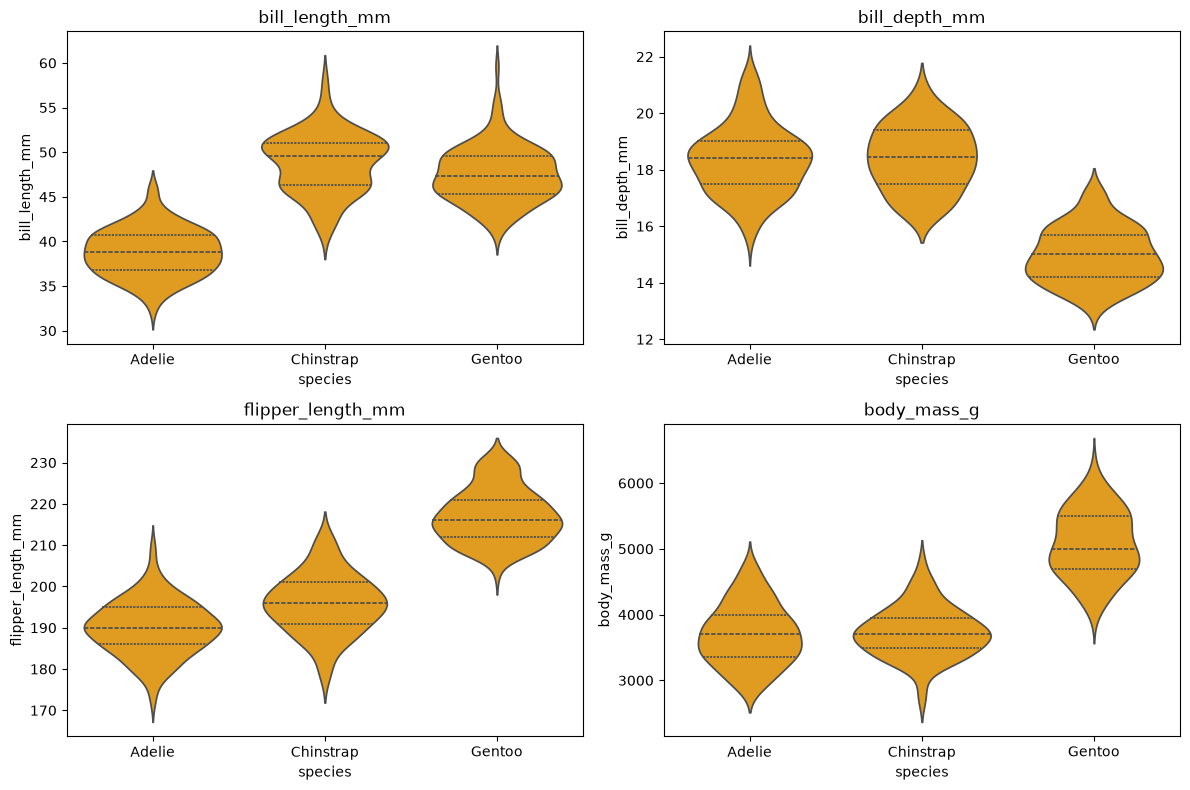

In [7]:
# mögliche Eingaben für Vorhersage
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

plt.figure(figsize=(12, 8))

for i, feat in enumerate(features, 1):
    plt.subplot(2, 2, i)
    sns.violinplot(data=df, x="species", y=feat, 
                   color="orange", inner="quartile")
    plt.title(feat)

plt.tight_layout()
plt.show()

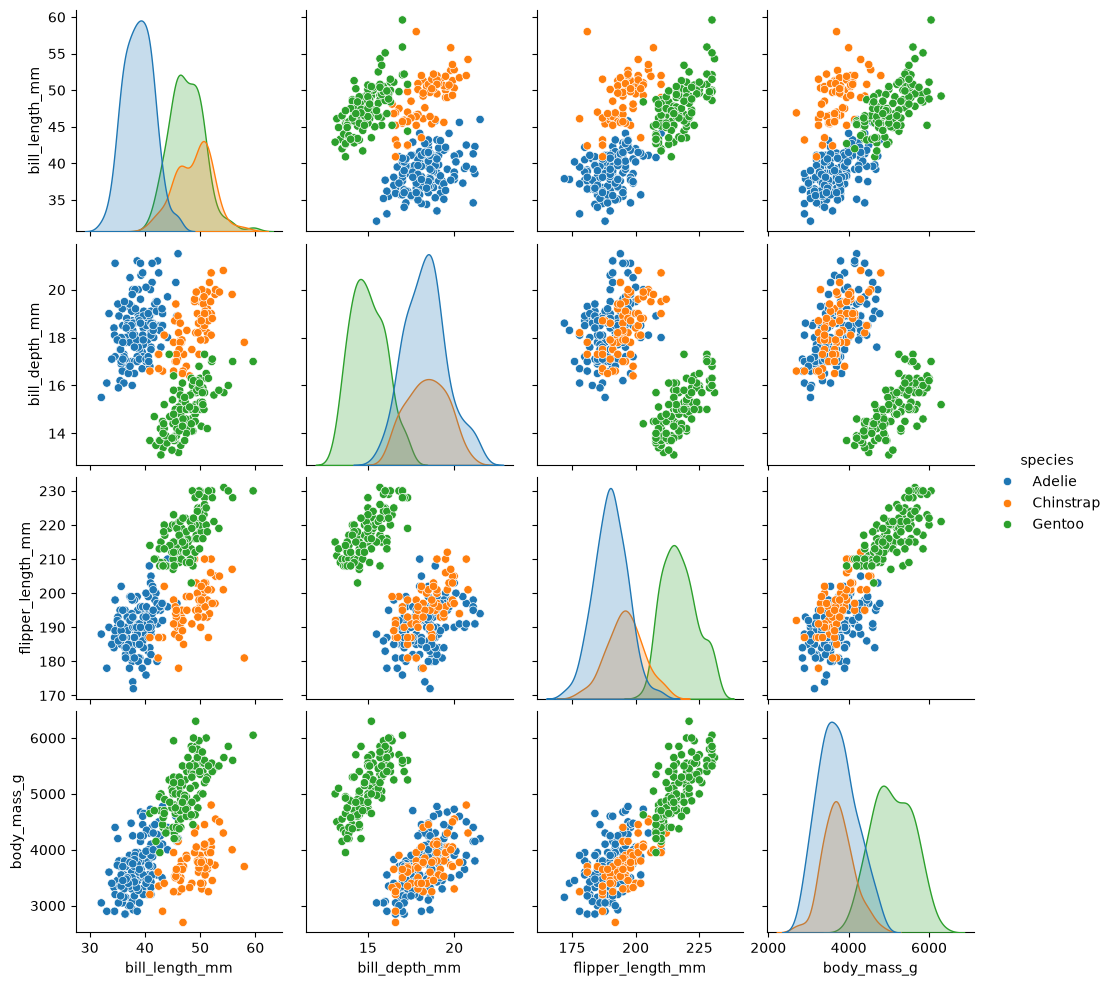

In [8]:
sns.pairplot(df.dropna(), hue="species")
plt.show()

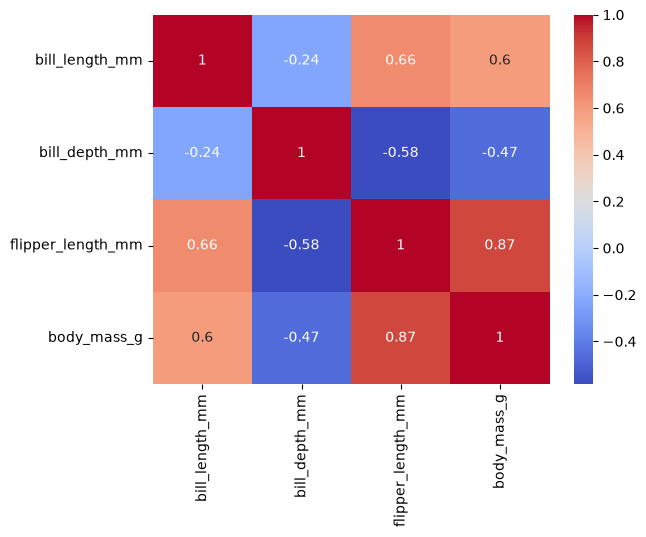

In [9]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.show()

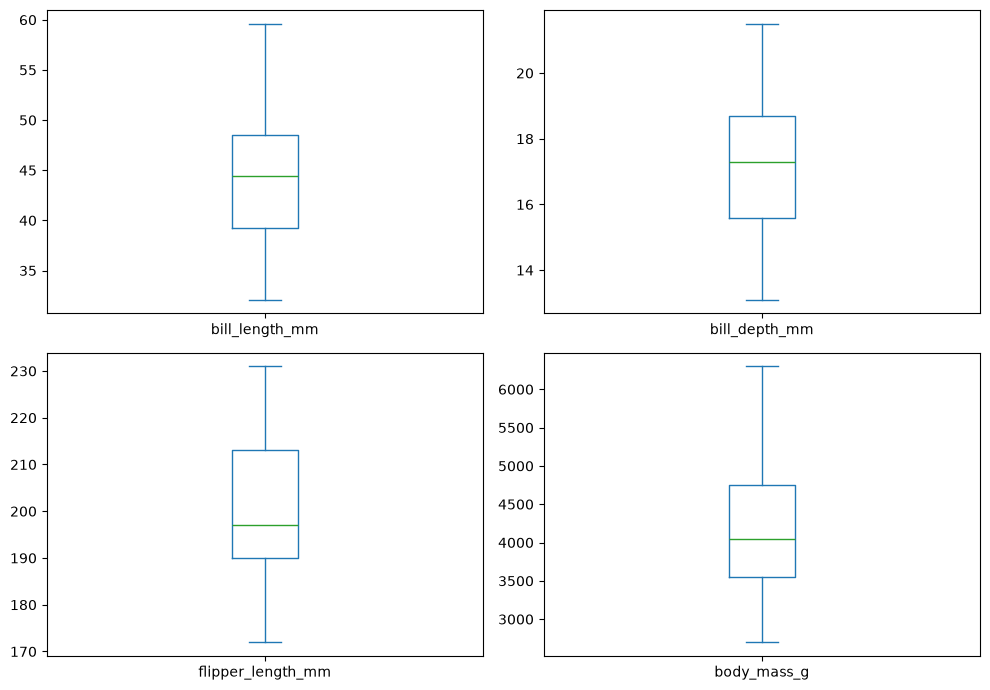

In [10]:
# Suche nach Ausreißern

num_cols = df.select_dtypes(include="number").columns

df[num_cols].plot(
    kind="box",
    subplots=True,
    layout=(2, 2),
    figsize=(10, 7)
)
plt.tight_layout()
plt.show()

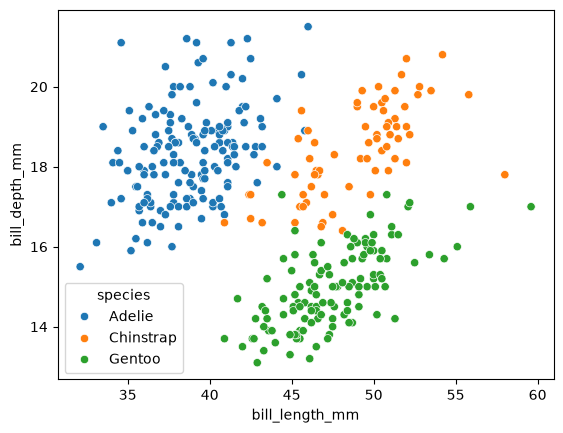

In [11]:
sns.scatterplot(
    data=df,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="species"
)
plt.show()

In [12]:
# Datenbereinigung
# Einziges erkanntes Problem: leere Zellen, "NaN"

# alle Zeilen mit nan raus
df_clean = df.dropna()

In [13]:

# # Künstliche Ausreißer
df_outliers = df.copy()

# # drei Zeilen
rows = df_outliers.dropna(
    subset=["bill_length_mm", "body_mass_g"]
).index[:3]

# # Werte ändern
df_outliers.loc[rows[0], "bill_length_mm"] = 100
df_outliers.loc[rows[1], "body_mass_g"] = 10000
df_outliers.loc[rows[2], "bill_length_mm"] = 110

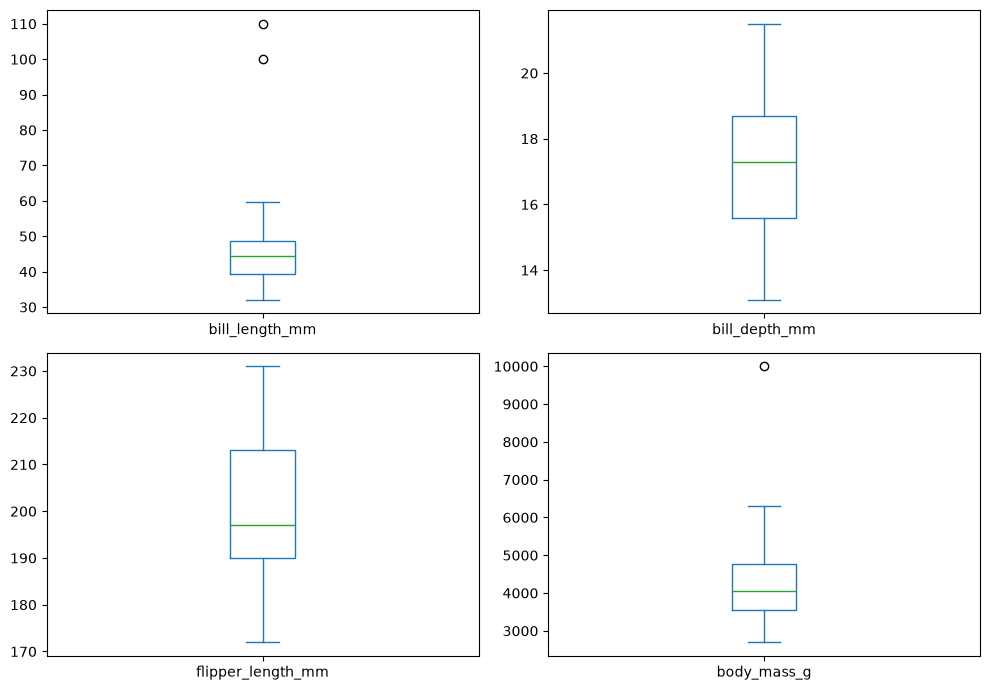

In [14]:
# selbe Graphiken wie oben

num_cols = df_outliers.select_dtypes(include="number").columns

df_outliers[num_cols].plot(
    kind="box",
    subplots=True,
    layout=(2, 2),
    figsize=(10, 7)
)
plt.tight_layout()
plt.show()

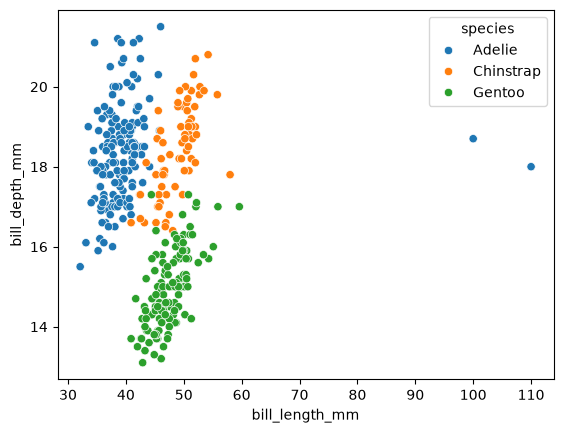

In [15]:
sns.scatterplot(
    data=df_outliers,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="species"
)
plt.show()